In [3]:
import uproot 

import sys
sys.path.append("../src")
import tutorial_cuts
from tutorial_cuts import cut_isolation_et, cut_photon_reconstruction
import features
from features import calc_myy
import plotting
from plotting import plot_data

branches = [
    "photon_n", "trigP", "photon_pt", "photon_eta", "photon_phi", 
    "photon_E", "photon_isTightID", "photon_ptcone30", "photon_etcone20",

    "mcWeight", "scaleFactor_PILEUP", "scaleFactor_PHOTON",
    "scaleFactor_PhotonTRIGGER", "XSection", "SumWeights",

    "jet_n", "jet_pt", "jet_eta", "jet_phi", "jet_jvt"
]

In [5]:
arrays = uproot.open("../data/processed/data_A_preselection.root:mini").arrays(branches, library="ak")

cutflow = {}
cutflow["preselected events"] = len(arrays)

arrays = arrays[cut_isolation_et(arrays.photon_etcone20)]
cutflow["photon isolation et"] = len(arrays)

arrays = arrays[cut_photon_reconstruction(arrays.photon_isTightID)]
cutflow["photon reconstruction"] = len(arrays)

out_path = "../data/processed/data_A_tut_cuts.root"

with uproot.recreate(out_path) as f:
    f["mini"] = {name: arrays[name] for name in arrays.fields}

for name, n in cutflow.items():
    print(f"{name:20s} {n:>10d}  ({n / cutflow['preselected events']:.1%})")

preselected events       250606  (100.0%)
photon isolation et       74177  (29.6%)
photon reconstruction      22350  (8.9%)


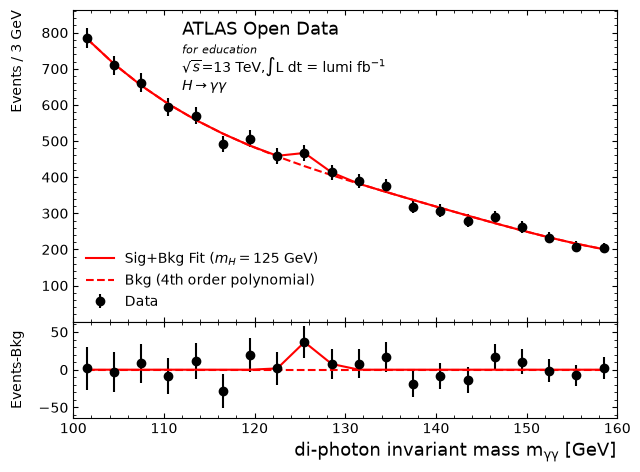

In [6]:
myy = calc_myy(arrays.photon_pt, arrays.photon_eta, arrays.photon_phi, arrays.photon_E)
plot_data(myy)